# 实验 5　人物识别与别名归一

## 任务要求

1. 选取 8—15 位核心人物，建立基础人物名单。
2. 整理别名、字、称号等写法（如“刘备 / 玄德 / 刘皇叔”），设计归一规则。
3. 统计主要人物的出现频次，输出 Top20 榜单。
4. 写出这种方法的局限：哪些称谓可能有歧义，哪些人物仍然可能被漏掉。

## 归一规则

- 别名词典：`data/lexicons/character_aliases.csv`（长表：标准名, 别名）。
- 为每个人物构造正则，**长别名优先匹配**，避免“刘玄德”又被“玄德”重复计一次。
- 只做字符串匹配与归一，不做上下文消歧。

In [1]:
# 让 notebook 在 notebooks/ 或仓库根目录下都能找到 src/ 包
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "sanguo_nlp").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from sanguo_nlp.paths import FIGURES_DIR, TABLES_DIR, ensure_output_dirs

ensure_output_dirs()
print("已定位仓库根目录:", ROOT.name)

已定位仓库根目录: three-kingdoms-nlp-lab


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from sanguo_nlp.corpus import read_raw
from sanguo_nlp.lexicons import load_aliases
from sanguo_nlp.mentions import count_mentions
from sanguo_nlp.plotting import use_chinese_font

use_chinese_font()

aliases = load_aliases()
print("人物数量:", len(aliases))
for name, values in list(aliases.items())[:4]:
    print(f"  {name}: {values}")

人物数量: 16
  刘备: ['刘玄德', '刘豫州', '刘皇叔', '刘备', '玄德']
  曹操: ['曹孟德', '曹阿瞒', '曹操', '孟德', '曹公']
  诸葛亮: ['诸葛孔明', '诸葛亮', '孔明', '卧龙']
  孙权: ['孙仲谋', '孙权', '仲谋', '吴主']


In [3]:
text = read_raw()
counts = count_mentions(text, aliases)

freq = pd.DataFrame(
    sorted(counts.items(), key=lambda item: -item[1]), columns=["人物", "频次"]
).reset_index(drop=True)
freq.to_csv(TABLES_DIR / "character_frequencies.csv", index=False, encoding="utf-8-sig")

print("人物提及次数 Top20:")
print(freq.head(20).to_string(index=False))

人物提及次数 Top20:
 人物   频次
 刘备 2224
诸葛亮 1901
 曹操 1037
 关羽  981
 赵云  447
 张飞  433
 吕布  383
 孙权  380
 魏延  341
司马懿  327
 姜维  302
 周瑜  301
 袁绍  281
 马超  230
 黄忠  198
 董卓  124


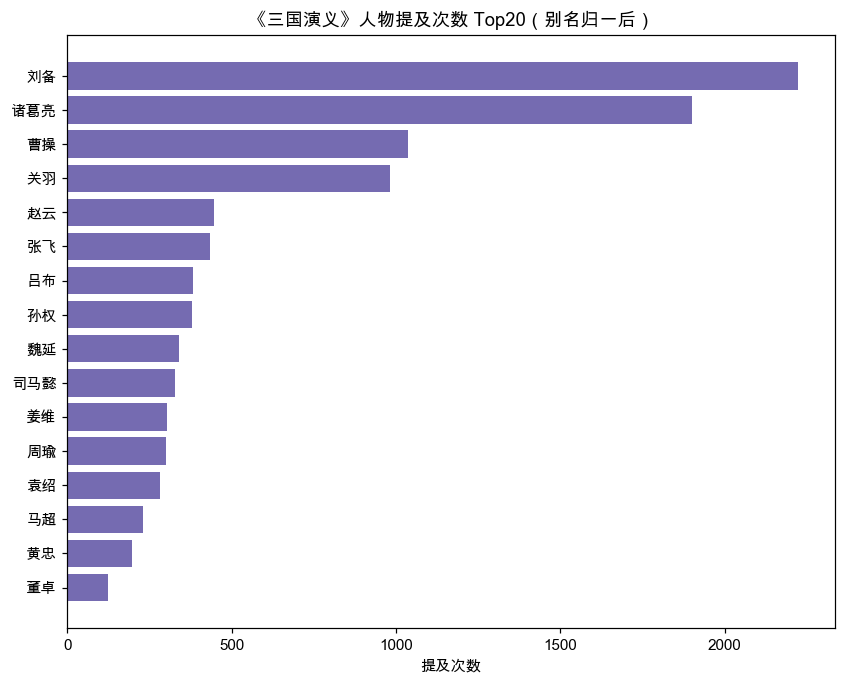

In [4]:
top20 = freq.head(20)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top20["人物"], top20["频次"], color="#756bb1")
ax.invert_yaxis()
ax.set_xlabel("提及次数")
ax.set_title("《三国演义》人物提及次数 Top20（别名归一后）")
fig.savefig(FIGURES_DIR / "character_frequencies.png")
plt.show()

## 方法局限与实验记录

- **职位称谓有歧义**：“丞相”“将军”在不同时期可能指不同人物（曹操、诸葛亮都做过丞相），因此不能把职位直接等同于某个人。
- **别名可能撞名**：单字简称（如“德”“公”）会带来大量误匹配，本词典只收录至少 2 字、指向较明确的别名。
- **仍可能漏人**：只覆盖了预先定义的 16 人，次要人物、女性人物与群体称谓（如“众将”）都会被漏掉。
- **验证方式**：与人物百科等权威资料抽样对照；在文本中抽查若干回，确认归一后的上下文一致。

**实验记录**

- 本实验未出现报错；AI 助手生成了初始别名表，随后通过人工抽样和与资料对照进行了核验。